# Rajuk Image Level Classifier — Bare Neural Network (MLP)

**Architecture:** Fully-connected Multi-Layer Perceptron (MLP) only.  
No convolutions, no pretrained weights, no feature extractors.

**Input:** Raw flattened pixel values → 128×128×3 = **49,152 features per image**

**Pipeline:**
1. Mount Drive & Import Libraries  
2. Configuration  
3. Load Labels  
4. Collect Paths & Leakage-Free Split  
5. Sample Image Preview  
6. Dataset (flatten pixels → MLP input)  
7. DataLoaders  
8. MLP Architecture  
9. Weighted Loss & Helpers  
10. K-Fold Cross-Validation  
11. Fine-tune & Evaluate  
12. Classification Report & Confusion Matrix  
13. Learning Curves (Train / Val / Test error by dataset size)  
14. Full Training History  
15. Save Model  
16. Sanity Check

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import Libraries

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 3. Configuration

In [3]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DRIVE_BASE    = Path('/content/drive/MyDrive/ML_Project')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet - Sheet1.csv'

# ── Image & MLP settings ───────────────────────────────────────────────────────
CLASS_NAMES   = ['negative', 'moderate', 'positive']
ALLOWED_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp'}

# 128x128 → 49,152 input features per image
# RAM: 2700 images * 49152 * 4 bytes (float32) = ~530 MB — safe for 12.7 GB
IMAGE_SIZE    = (128, 128)
INPUT_DIM     = IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3   # 49,152

# ── Hyper-parameters ───────────────────────────────────────────────────────────
BATCH_SIZE    = 32
LR            = 1e-3
NUM_EPOCHS    = 60
KFOLD_SPLITS  = 5
PATIENCE      = 10
WEIGHT_DECAY  = 1e-3
DROPOUT       = 0.4

# ── Learning-curve steps ───────────────────────────────────────────────────────
DATASET_STEPS = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

print('Configuration loaded.')
print(f'  Image size : {IMAGE_SIZE}')
print(f'  Input dim  : {INPUT_DIM:,} features per image')
print(f'  Batch size : {BATCH_SIZE}')
print(f'  Epochs     : {NUM_EPOCHS}')

Configuration loaded.
  Image size : (128, 128)
  Input dim  : 49,152 features per image
  Batch size : 32
  Epochs     : 60


## 4. Load Labels

In [ ]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target):
    for col in df.columns:
        if normalize_header(col) == target:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate',  'moderate': 'moderate',
               'n': 'negative',  'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(f'No dataset file found at {DRIVE_BASE}.')

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Level column not found.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows | {len(label_map):,} valid labels | source: {source_path.name}')

Loaded 161 rows | 160 valid labels | source: Rajuk_ML_DataSet.xlsx


## 5. Collect Paths & Leakage-Free Split

Split is by **unique subject ID** first so no subject's augmented copy
leaks into val/test. Augmented images go to training only.

In [5]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_all_raw(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_all_raw(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_all_raw(REAL_DIR,      label_map)

print(f'Augmented images         : {len(aug_paths):,}')
print(f'Real images              : {len(real_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

# ── Leakage-free split by unique subject ID ────────────────────────────────────
unique_indices     = sorted(set(
    parse_image_index(p.stem.strip()) for p in real_paths
    if parse_image_index(p.stem.strip()) is not None
))
unique_labels_list = [label_map[i] for i in unique_indices]
all_uq             = np.arange(len(unique_indices))

trainval_uq, test_uq = train_test_split(
    all_uq, test_size=0.15, random_state=SEED, stratify=unique_labels_list
)
train_uq, val_uq = train_test_split(
    trainval_uq, test_size=0.15/0.85, random_state=SEED,
    stratify=np.array(unique_labels_list)[trainval_uq]
)

train_img_ids = set(np.array(unique_indices)[train_uq])
val_img_ids   = set(np.array(unique_indices)[val_uq])
test_img_ids  = set(np.array(unique_indices)[test_uq])

train_paths_final, train_labels_final = [], []
val_paths_final,   val_labels_final   = [], []
test_paths_final,  test_labels_final  = [], []

for p, lbl in zip(aug_paths, aug_labels):
    if parse_image_index(p.stem.strip()) in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)

for p, lbl in zip(real_paths, real_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

N_total = len(train_paths_final) + len(val_paths_final) + len(test_paths_final)
print(f'\nLeakage-free split:')
print(f'  Train (real + aug) : {len(train_paths_final):,}  ({100*len(train_paths_final)/N_total:.1f} %)')
print(f'  Val   (real only)  : {len(val_paths_final):,}  ({100*len(val_paths_final)/N_total:.1f} %)')
print(f'  Test  (real only)  : {len(test_paths_final):,}  ({100*len(test_paths_final)/N_total:.1f} %)')

counts = np.bincount(train_labels_final + val_labels_final + test_labels_final,
                     minlength=len(CLASS_NAMES))
print('\nClass distribution (total):')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

Augmented images         : 2,560
Real images              : 160
Skipped (no index)       : 0
Skipped (no label match) : 0

Leakage-free split:
  Train (real + aug) : 1,904  (97.5 %)
  Val   (real only)  : 24  (1.2 %)
  Test  (real only)  : 24  (1.2 %)

Class distribution (total):
  negative  : 1,080
  moderate  : 505
  positive  : 367


## 6. 📷 Sample Images — Data Preview

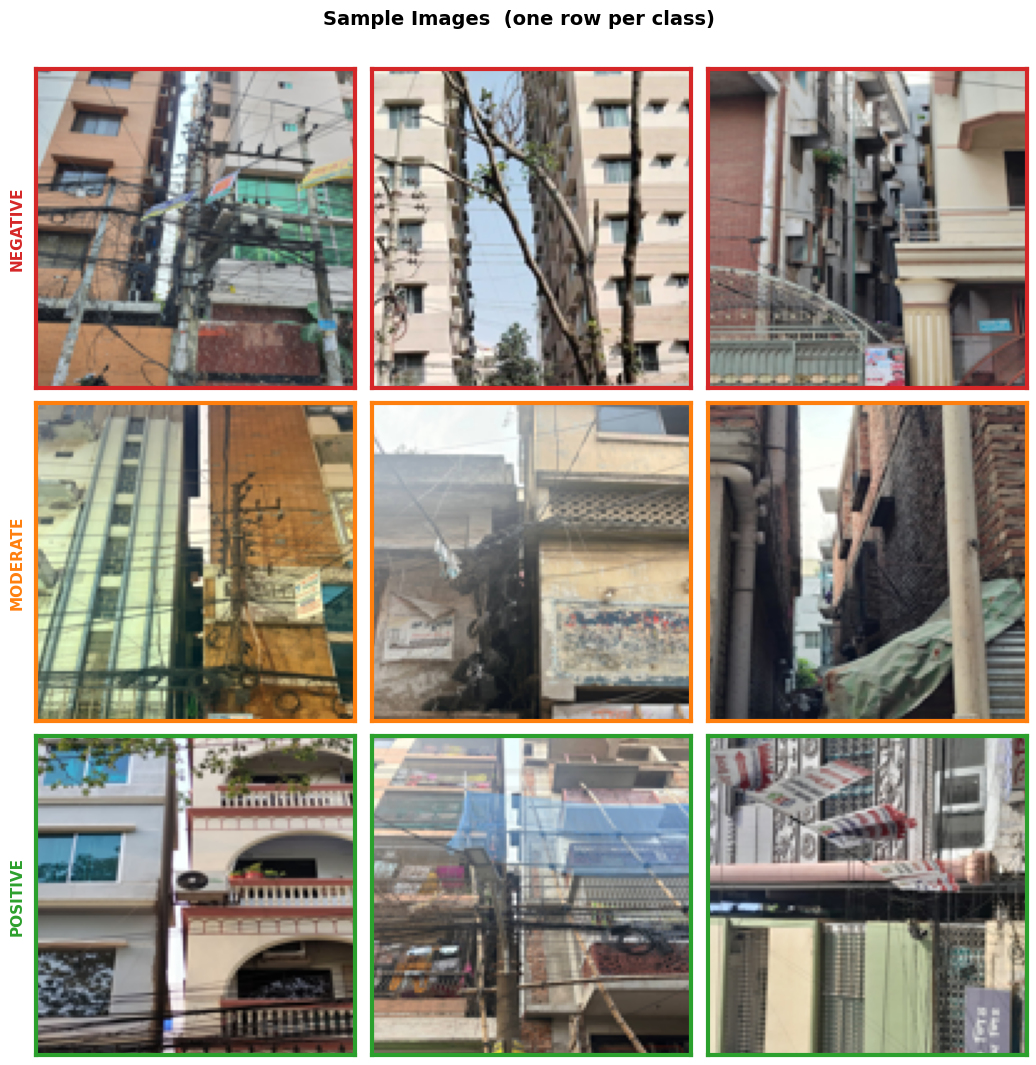

Sample images displayed.


In [6]:
SAMPLES_PER_CLASS = 3
label_to_real_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(real_paths, real_labels):
    label_to_real_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_real_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sample images displayed.')

## 7. Dataset — Flatten Pixels into MLP Input

An MLP takes a **1D vector** as input. Each image is:
- Resized to 128×128
- Normalised to [0, 1]
- Flattened: 128 × 128 × 3 = **49,152 features**

For the training set, we apply **random flips and slight brightness jitter** before
flattening to add diversity. Val/test are flattened as-is.

RAM estimate: 2,700 images × 49,152 × 4 bytes ≈ **530 MB** — well within 12.7 GB.

In [7]:
import random
from PIL import ImageEnhance, ImageOps


def augment_pil(img: Image.Image) -> Image.Image:
    """Lightweight augmentation for MLP — purely pixel-level, no spatial ops."""
    if random.random() < 0.5:
        img = ImageOps.mirror(img)                          # horizontal flip
    if random.random() < 0.3:
        img = ImageOps.flip(img)                            # vertical flip
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Brightness(img).enhance(factor)  # brightness jitter
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Contrast(img).enhance(factor)    # contrast jitter
    if random.random() < 0.3:
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Color(img).enhance(factor)       # saturation jitter
    return img


def pil_to_flat_tensor(img: Image.Image) -> torch.Tensor:
    """Convert PIL image → normalised float32 tensor of shape (INPUT_DIM,)."""
    arr = np.asarray(img.resize(IMAGE_SIZE), dtype=np.float32) / 255.0
    return torch.from_numpy(arr.flatten())   # (49152,)


class RajukFlatDataset(Dataset):
    """
    MLP dataset — stores PIL images in RAM (uint8, ~530 MB for 2700 images)
    and converts to flat float32 tensors on the fly in __getitem__.

    If augment=True (training set), random flips/brightness applied per call
    so every epoch sees slightly different pixel values.
    """

    def __init__(self, image_paths, labels, augment: bool = False):
        self.labels  = labels
        self.augment = augment
        n = len(image_paths)
        ram_mb = n * IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3 / 1e6
        print(f'  Caching {n:,} PIL images … (est. {ram_mb:.0f} MB RAM)')
        self.images = []
        for p in image_paths:
            with Image.open(p) as img:
                self.images.append(img.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR))
        print(f'  Done. augment={augment}')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.augment:
            img = augment_pil(img)
        return pil_to_flat_tensor(img), self.labels[idx]


if len(train_paths_final) == 0:
    raise ValueError('No labeled images found. Check folder paths and label mapping.')

print('Building datasets:')
train_dataset = RajukFlatDataset(train_paths_final, train_labels_final, augment=True)
val_dataset   = RajukFlatDataset(val_paths_final,   val_labels_final,   augment=False)
test_dataset  = RajukFlatDataset(test_paths_final,  test_labels_final,  augment=False)

total_mb = (len(train_dataset)+len(val_dataset)+len(test_dataset)) * IMAGE_SIZE[0]*IMAGE_SIZE[1]*3 / 1e6
print(f'\nTrain: {len(train_dataset):,}  Val: {len(val_dataset):,}  Test: {len(test_dataset):,}')
print(f'Total image RAM: ~{total_mb:.0f} MB')

# Quick shape check
x0, y0 = train_dataset[0]
print(f'\nSample tensor shape : {x0.shape}  (should be ({INPUT_DIM},))')
print(f'Sample label        : {y0}  ({CLASS_NAMES[y0]})')

Building datasets:
  Caching 1,904 PIL images … (est. 94 MB RAM)
  Done. augment=True
  Caching 24 PIL images … (est. 1 MB RAM)
  Done. augment=False
  Caching 24 PIL images … (est. 1 MB RAM)
  Done. augment=False

Train: 1,904  Val: 24  Test: 24
Total image RAM: ~96 MB

Sample tensor shape : torch.Size([49152])  (should be (49152,))
Sample label        : 1  (moderate)


## 8. DataLoaders

In [8]:
pin = torch.cuda.is_available()
NW  = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NW, pin_memory=pin)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)

print(f'Train : {len(train_dataset):,} samples  ({len(train_loader)} batches)')
print(f'Val   : {len(val_dataset):,} samples  ({len(val_loader)} batches)')
print(f'Test  : {len(test_dataset):,} samples  ({len(test_loader)} batches)')

Train : 1,904 samples  (60 batches)
Val   : 24 samples  (1 batches)
Test  : 24 samples  (1 batches)


## 9. MLP Architecture

A pure **Multi-Layer Perceptron** — only `nn.Linear`, `nn.BatchNorm1d`,
`nn.ReLU`, and `nn.Dropout` layers. Zero convolutions.

```
Input  :  49,152  (128×128×3 flattened pixels)
  └─ Linear(49152 → 2048) + BN + ReLU + Dropout
  └─ Linear(2048  → 1024) + BN + ReLU + Dropout
  └─ Linear(1024  →  512) + BN + ReLU + Dropout
  └─ Linear(512   →  256) + BN + ReLU + Dropout
  └─ Linear(256   →    3) — raw logits
Output :  3 class logits
```

In [9]:
class RajukMLP(nn.Module):
    """
    Bare Multi-Layer Perceptron for image classification.
    Input: flat pixel vector of length input_dim (49,152 for 128x128 RGB).
    No convolutions, no attention, no pretrained weights.
    """

    def __init__(self, input_dim: int, num_classes: int, dropout: float = 0.4):
        super().__init__()

        def block(in_f, out_f):
            return nn.Sequential(
                nn.Linear(in_f, out_f),
                nn.BatchNorm1d(out_f),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            )

        self.net = nn.Sequential(
            block(input_dim, 2048),
            block(2048,      1024),
            block(1024,       512),
            block(512,        256),
            nn.Linear(256, num_classes),   # output logits — no activation
        )

    def forward(self, x):
        return self.net(x)


_tmp = RajukMLP(INPUT_DIM, len(CLASS_NAMES))
total_params = sum(p.numel() for p in _tmp.parameters())
print(f'MLP total parameters: {total_params:,}')
print('Layers:')
for name, mod in _tmp.named_modules():
    if isinstance(mod, nn.Linear):
        print(f'  {name:30s} {mod}')
del _tmp

MLP total parameters: 103,428,099
Layers:
  net.0.0                        Linear(in_features=49152, out_features=2048, bias=True)
  net.1.0                        Linear(in_features=2048, out_features=1024, bias=True)
  net.2.0                        Linear(in_features=1024, out_features=512, bias=True)
  net.3.0                        Linear(in_features=512, out_features=256, bias=True)
  net.4                          Linear(in_features=256, out_features=3, bias=True)


## 10. Weighted Loss & Training Helpers

In [10]:
# ── Weighted loss to handle class imbalance ────────────────────────────────────
train_labels_arr = np.array(train_labels_final, dtype=np.int64)
class_counts     = np.bincount(train_labels_arr, minlength=len(CLASS_NAMES))
class_weights    = torch.tensor(1.0 / (class_counts + 1e-6), dtype=torch.float32).to(device)
class_weights   /= class_weights.sum()

criterion = nn.CrossEntropyLoss(weight=class_weights)

print('Class counts & weights in training set:')
for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights.cpu()):
    print(f'  {name:10s}: {cnt:,} samples  →  weight {w:.4f}')


# ── Train / evaluate ──────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = correct = total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss   = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += X.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_true = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss   = criterion(logits, y)
        total_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total   += X.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_true


def make_model():
    m   = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
    opt = optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NUM_EPOCHS, eta_min=1e-6)
    return m, opt, sch


print('\nHelpers defined.')

Class counts & weights in training set:
  negative  : 1,054 samples  →  weight 0.1642
  moderate  : 493 samples  →  weight 0.3510
  positive  : 357 samples  →  weight 0.4848

Helpers defined.


## 11. K-Fold Cross-Validation on Real Training Images Only

K-Fold runs on **real training images only** (not augmented copies) so
fold accuracy numbers are honest — no near-duplicate images leaking
across fold boundaries.

In [11]:
# Build a real-only training dataset for K-Fold
real_train_paths  = [p for p in train_paths_final
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]
real_train_labels = [l for p, l in zip(train_paths_final, train_labels_final)
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]

print(f'Real training images for K-Fold: {len(real_train_paths):,}')

kfold_dataset   = RajukFlatDataset(real_train_paths, real_train_labels, augment=True)
kfold_labels    = np.array(real_train_labels, dtype=np.int64)
kfold_indices   = np.arange(len(kfold_dataset))

min_cls = np.min(np.bincount(kfold_labels, minlength=len(CLASS_NAMES)))
k       = min(KFOLD_SPLITS, int(min_cls))
kfold   = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)

fold_val_accs     = []
best_global_acc   = -1.0
best_global_state = None

for fold, (tr, va) in enumerate(kfold.split(kfold_indices, kfold_labels)):
    print(f'\n{"─"*58}')
    print(f'  Fold {fold+1}/{k}   |   train={len(tr):,}   val={len(va):,}')
    print(f'{"─"*58}')

    fold_train_loader = DataLoader(
        Subset(kfold_dataset, tr),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )
    fold_val_loader = DataLoader(
        Subset(kfold_dataset, va),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NW, pin_memory=pin
    )

    model, optimizer, scheduler = make_model()
    best_fold_acc   = -1.0
    best_fold_state = None
    patience_ctr    = 0

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, fold_train_loader, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, fold_val_loader)
        scheduler.step()

        print(f'  Ep {epoch+1:02d}/{NUM_EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f}  |  '
              f'Val   Loss={vl_loss:.4f} Acc={vl_acc:.4f}')

        if vl_acc > best_fold_acc:
            best_fold_acc   = vl_acc
            patience_ctr    = 0
            best_fold_state = {k2: v.cpu() for k2, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}.')
                break

    fold_val_accs.append(best_fold_acc)
    print(f'  → Fold {fold+1} best val acc: {best_fold_acc:.4f}')

    if best_fold_acc > best_global_acc:
        best_global_acc   = best_fold_acc
        best_global_state = best_fold_state

print(f'\nCross-val accuracies : {[f"{a:.4f}" for a in fold_val_accs]}')
print(f'Mean CV accuracy     : {np.mean(fold_val_accs):.4f} ± {np.std(fold_val_accs):.4f}')

Real training images for K-Fold: 112
  Caching 112 PIL images … (est. 6 MB RAM)
  Done. augment=True

──────────────────────────────────────────────────────────
  Fold 1/5   |   train=89   val=23
──────────────────────────────────────────────────────────
  Ep 01/60  Train Loss=1.1899 Acc=0.3371  |  Val   Loss=1.6972 Acc=0.5652
  Ep 02/60  Train Loss=1.1803 Acc=0.3820  |  Val   Loss=1.9008 Acc=0.6087
  Ep 03/60  Train Loss=1.0698 Acc=0.4270  |  Val   Loss=2.2382 Acc=0.3913
  Ep 04/60  Train Loss=1.1199 Acc=0.4270  |  Val   Loss=2.0310 Acc=0.3478
  Ep 05/60  Train Loss=1.1750 Acc=0.3820  |  Val   Loss=2.0816 Acc=0.5217
  Ep 06/60  Train Loss=1.0656 Acc=0.4270  |  Val   Loss=1.5472 Acc=0.5217
  Ep 07/60  Train Loss=1.0812 Acc=0.5169  |  Val   Loss=1.3925 Acc=0.4783
  Ep 08/60  Train Loss=1.0603 Acc=0.4607  |  Val   Loss=1.3868 Acc=0.3913
  Ep 09/60  Train Loss=1.0745 Acc=0.4831  |  Val   Loss=1.0576 Acc=0.4348
  Ep 10/60  Train Loss=0.9493 Acc=0.5281  |  Val   Loss=1.2589 Acc=0.4348
  Ep 

## 12. Fine-tune Best Model on Full Train Set → Evaluate on Val + Test

In [12]:
final_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
final_model.load_state_dict({k: v.to(device) for k, v in best_global_state.items()})

ft_optimizer = optim.AdamW(final_model.parameters(), lr=LR / 5, weight_decay=WEIGHT_DECAY)

print('Fine-tuning on full training split …')
for epoch in range(5):
    t_loss, t_acc = train_one_epoch(final_model, train_loader, ft_optimizer)
    print(f'  FT Epoch {epoch+1}/5  Loss={t_loss:.4f}  Acc={t_acc:.4f}')

val_loss,  val_acc,  val_preds,  val_true  = evaluate(final_model, val_loader)
test_loss, test_acc, test_preds, test_true = evaluate(final_model, test_loader)

print(f'\n{"="*50}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{"="*50}')

Fine-tuning on full training split …
  FT Epoch 1/5  Loss=0.9257  Acc=0.5509
  FT Epoch 2/5  Loss=0.5925  Acc=0.7085
  FT Epoch 3/5  Loss=0.3294  Acc=0.8603
  FT Epoch 4/5  Loss=0.2169  Acc=0.9259
  FT Epoch 5/5  Loss=0.1435  Acc=0.9543

  Validation — Loss: 1.8558   Acc: 0.2083
  Test       — Loss: 1.5627   Acc: 0.4583


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.67      0.62      0.64        13
    moderate       0.33      0.17      0.22         6
    positive       0.22      0.40      0.29         5

    accuracy                           0.46        24
   macro avg       0.41      0.39      0.38        24
weighted avg       0.49      0.46      0.46        24



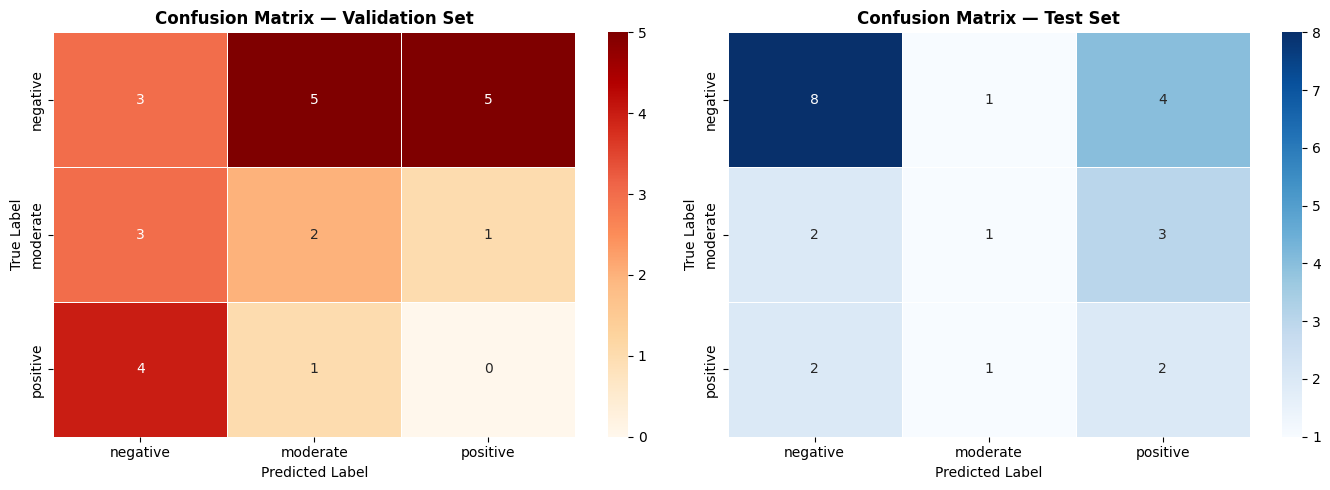

In [13]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  val_true,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, test_true, 'Confusion Matrix — Test Set',       'Blues'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 14. Learning Curves — Error vs. Dataset Size

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |

In [14]:
def train_and_measure(n_train: int):
    actual_n = min(n_train, len(train_dataset))
    if actual_n < len(CLASS_NAMES):
        return None

    sub_idx, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=actual_n,
        random_state=SEED,
        stratify=train_labels_arr
    )
    sub_loader = DataLoader(
        Subset(train_dataset, sub_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )

    m, opt, sch = make_model()
    for _ in range(min(15, NUM_EPOCHS)):
        train_one_epoch(m, sub_loader, opt)
        sch.step()

    tr_loss, _, _, _ = evaluate(m, sub_loader)
    vl_loss, _, _, _ = evaluate(m, val_loader)
    te_loss, _, _, _ = evaluate(m, test_loader)
    return tr_loss, vl_loss, te_loss


curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(train_dataset):
        print(f'  n={n}: exceeds train size ({len(train_dataset)}), skipping.')
        break
    print(f'  Training on n={n} …', end=' ', flush=True)
    result = train_and_measure(n)
    if result is None:
        print('skipped.'); continue
    tr_l, vl_l, te_l = result
    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

  Training on n=100 … train=1.0551  val=1.1262  test=1.0025
  Training on n=200 … train=0.8318  val=1.2026  test=1.0046
  Training on n=300 … train=0.3543  val=2.0432  test=1.4986
  Training on n=400 … train=0.3766  val=1.4534  test=1.9508
  Training on n=500 … train=0.4018  val=2.3749  test=2.1025
  Training on n=600 … train=0.8877  val=2.9738  test=2.4463
  Training on n=700 … train=0.5603  val=2.8337  test=2.5232
  Training on n=800 … train=0.2765  val=2.5171  test=2.1144
  Training on n=900 … train=0.2630  val=2.7993  test=2.6103
  Training on n=1000 … train=0.2741  val=2.3001  test=1.8279

Learning-curve data collected.


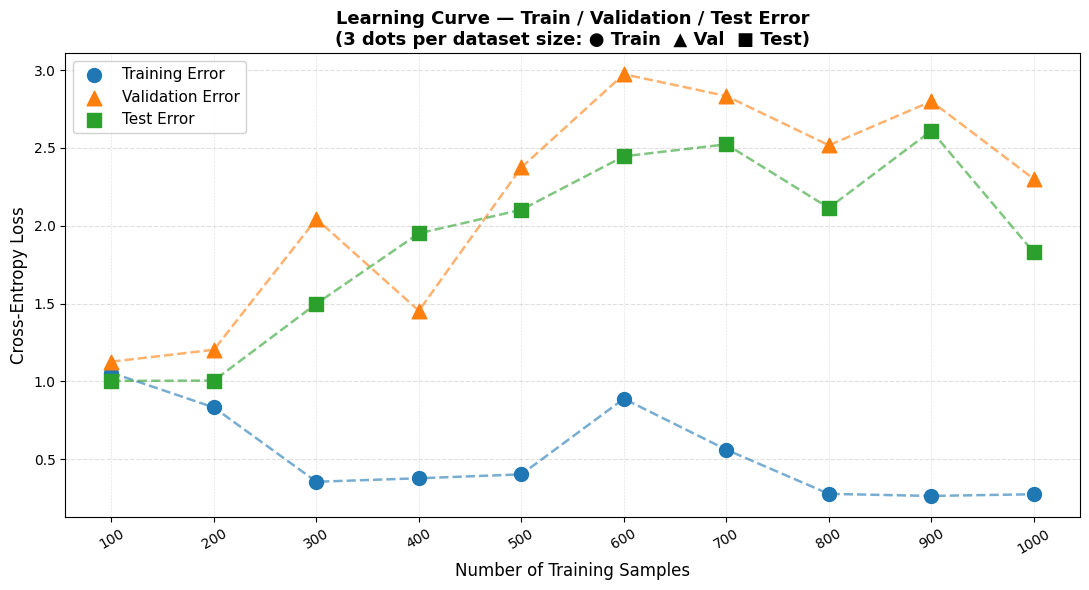

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()

## 15. Full Training History (MLP on Full Train Set)

In [16]:
history_model, history_opt, history_sch = make_model()
h = {'train_loss': [], 'val_loss': [], 'test_loss': [],
     'train_acc':  [], 'val_acc':  [], 'test_acc':  []}

best_acc_ht   = -1.0
best_state_ht = None
patience_ht   = 0

print(f'Training MLP for up to {NUM_EPOCHS} epochs …\n')
for epoch in range(NUM_EPOCHS):
    tr_l, tr_a = train_one_epoch(history_model, train_loader, history_opt)
    vl_l, vl_a, _, _ = evaluate(history_model, val_loader)
    te_l, te_a, _, _ = evaluate(history_model, test_loader)
    history_sch.step()

    for key, val in zip(
        ['train_loss','val_loss','test_loss','train_acc','val_acc','test_acc'],
        [tr_l, vl_l, te_l, tr_a, vl_a, te_a]
    ):
        h[key].append(val)

    print(f'Ep {epoch+1:02d}/{NUM_EPOCHS}  '
          f'Train L={tr_l:.4f} A={tr_a:.4f} | '
          f'Val L={vl_l:.4f} A={vl_a:.4f} | '
          f'Test L={te_l:.4f} A={te_a:.4f}')

    if vl_a > best_acc_ht:
        best_acc_ht   = vl_a
        patience_ht   = 0
        best_state_ht = {k2: v.cpu() for k2, v in history_model.state_dict().items()}
    else:
        patience_ht += 1
        if patience_ht >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}.')
            break

print(f'\nBest validation accuracy: {best_acc_ht:.4f}')

Training MLP for up to 60 epochs …

Ep 01/60  Train L=1.0750 A=0.4590 | Val L=1.2177 A=0.2917 | Test L=0.9942 A=0.5000
Ep 02/60  Train L=0.8348 A=0.5930 | Val L=1.6331 A=0.2500 | Test L=1.4274 A=0.5833
Ep 03/60  Train L=0.4779 A=0.7757 | Val L=1.6377 A=0.4167 | Test L=2.0682 A=0.3333
Ep 04/60  Train L=0.3623 A=0.8367 | Val L=2.2832 A=0.4167 | Test L=2.0891 A=0.5417
Ep 05/60  Train L=0.2526 A=0.8960 | Val L=2.1906 A=0.2083 | Test L=2.4146 A=0.4583
Ep 06/60  Train L=0.2158 A=0.9160 | Val L=2.2589 A=0.3750 | Test L=2.8898 A=0.2500
Ep 07/60  Train L=0.1544 A=0.9428 | Val L=3.2927 A=0.3750 | Test L=2.9502 A=0.4167
Ep 08/60  Train L=0.1405 A=0.9464 | Val L=3.6127 A=0.4583 | Test L=3.6372 A=0.5417
Ep 09/60  Train L=0.1564 A=0.9470 | Val L=4.5496 A=0.5833 | Test L=4.0657 A=0.6667
Ep 10/60  Train L=0.1368 A=0.9470 | Val L=2.1581 A=0.2917 | Test L=2.2211 A=0.3750
Ep 11/60  Train L=0.0899 A=0.9669 | Val L=2.9617 A=0.3333 | Test L=2.3673 A=0.4167
Ep 12/60  Train L=0.1454 A=0.9554 | Val L=3.0853 A=

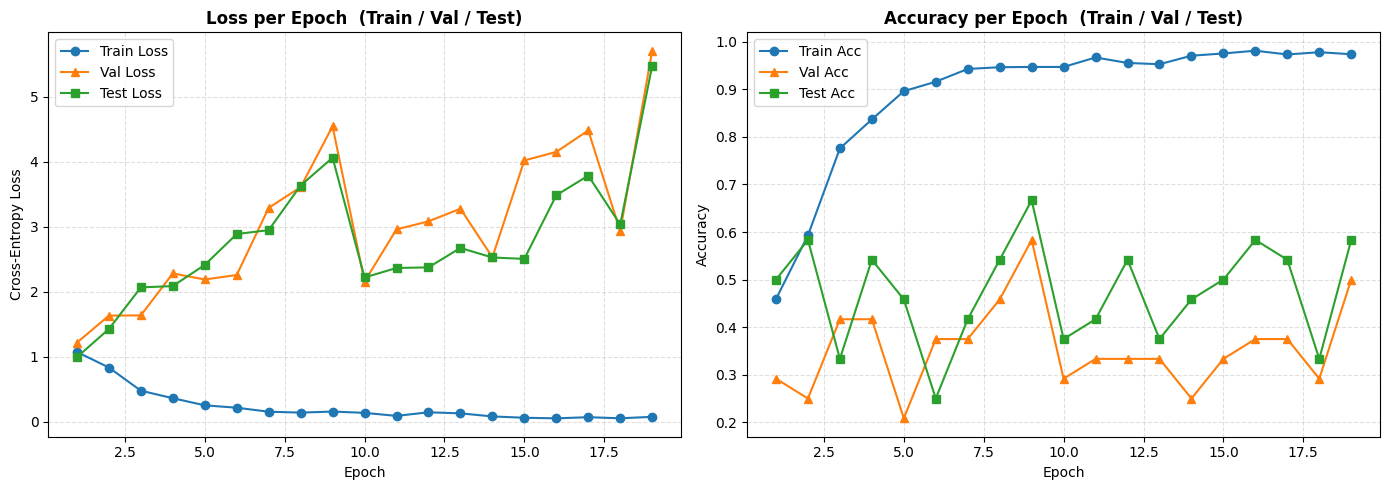

In [17]:
epochs_ran = range(1, len(h['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_ran, h['train_loss'], 'o-', color='#1f77b4', label='Train Loss')
ax1.plot(epochs_ran, h['val_loss'],   '^-', color='#ff7f0e', label='Val Loss')
ax1.plot(epochs_ran, h['test_loss'],  's-', color='#2ca02c', label='Test Loss')
ax1.set_title('Loss per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(linestyle='--', alpha=0.4)

ax2.plot(epochs_ran, h['train_acc'], 'o-', color='#1f77b4', label='Train Acc')
ax2.plot(epochs_ran, h['val_acc'],   '^-', color='#ff7f0e', label='Val Acc')
ax2.plot(epochs_ran, h['test_acc'],  's-', color='#2ca02c', label='Test Acc')
ax2.set_title('Accuracy per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('training_history.png', dpi=130, bbox_inches='tight')
plt.show()

## 16. Save Model

In [18]:
save_path = DRIVE_BASE / 'rajuk_mlp.pth'

artifact = {
    'model_state_dict' : best_state_ht,
    'class_names'      : CLASS_NAMES,
    'image_size'       : IMAGE_SIZE,
    'input_dim'        : INPUT_DIM,
    'label_source'     : str(source_path),
    'label_column'     : level_col,
    'best_val_acc'     : best_acc_ht,
    'kfold_val_accs'   : fold_val_accs,
    'train_size'       : len(train_dataset),
    'val_size'         : len(val_dataset),
    'test_size'        : len(test_dataset),
    'final_test_acc'   : test_acc,
}

torch.save(artifact, save_path)
print(f'Model saved to  : {save_path}')
print(f'Final test acc  : {test_acc:.4f}')

Model saved to  : /content/drive/MyDrive/ML_Project/rajuk_mlp.pth
Final test acc  : 0.4583


## 17. Sanity Check — Predict on Random Test Samples

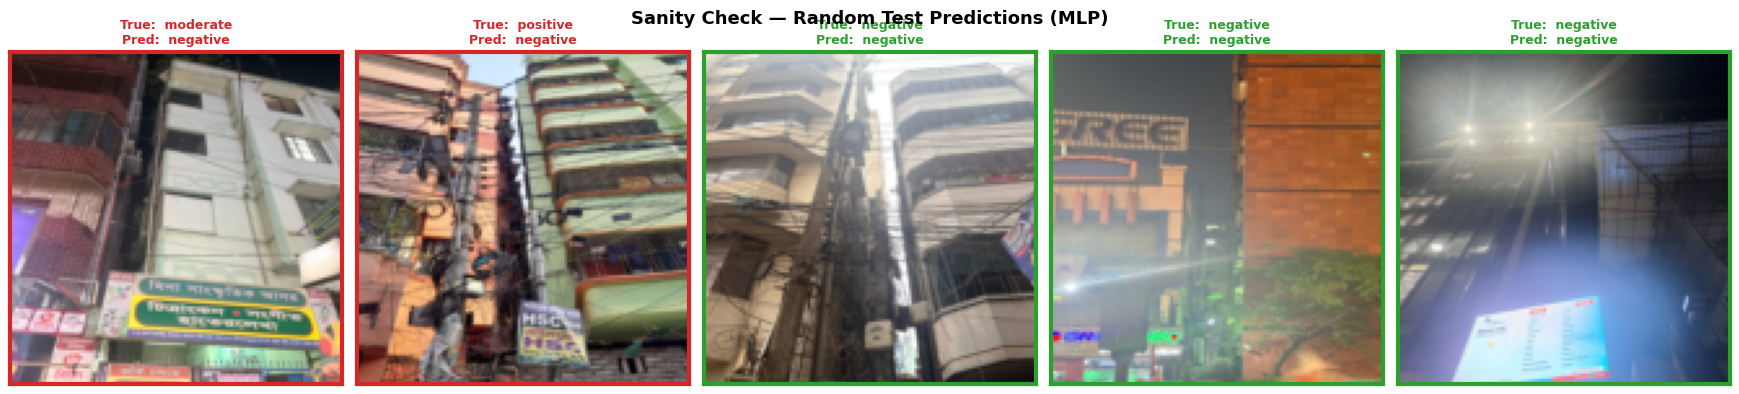

Sanity check complete.


In [19]:
best_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
best_model.load_state_dict({k: v.to(device) for k, v in best_state_ht.items()})
best_model.eval()

rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_dataset), size=min(5, len(test_dataset)), replace=False)

fig, axes = plt.subplots(1, len(sample), figsize=(len(sample) * 3.5, 4))
fig.suptitle('Sanity Check — Random Test Predictions (MLP)', fontsize=13, fontweight='bold')

with torch.no_grad():
    for ax, s_idx in zip(axes, sample):
        flat_tensor, true_lbl = test_dataset[int(s_idx)]
        logits   = best_model(flat_tensor.unsqueeze(0).to(device))
        pred_lbl = logits.argmax(1).item()

        # Reshape flat tensor back to image for display
        img_np = flat_tensor.numpy().reshape(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
        img_np = np.clip(img_np, 0, 1)

        ax.imshow(img_np)
        ax.set_xticks([]); ax.set_yticks([])

        colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
        ax.set_title(
            f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {CLASS_NAMES[pred_lbl]}',
            fontsize=9, color=colour, fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('sanity_predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sanity check complete.')